LangGraph + LangChain OpenAI 를 활용한 Assistant
- LangGraph는 LangChain의 에이전트 기능을 한 단계 더 발전시킨 라이브러리로, 순차적인 체인(Chain)이 아닌 상태 기반의 순환(Cycle) 그래프 구조를 설계할 때 사용합니다.

- 단순 챗봇을 넘어, '도구 사용(Tool Use)', '조건부 분기(Conditional Branching)', '상태 유지(State Management)'가 필요한 복잡한 어시스턴트를 만들 때 최적입니다.

In [ ]:
!pip install -q langchain-core langchain-openai langgraph python-dotenv ipython graphviz

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.9/43.9 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.7/216.7 kB 16.2 MB/s eta 0:00:00


In [ ]:
# 코드 상단 주석: 패키지 설치 명령어
# !pip install -q -U langgraph langchain-openai langchain-core

import os
from google.colab import userdata
from typing import Annotated, TypedDict
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_core.messages import BaseMessage

# 1. API 키 설정
os.environ["OPENAI_API_KEY"] = userdata.get('OPENAI_API_KEY')

# 2. 상태(State) 정의: 대화 메시지를 누적 저장
class State(TypedDict):



# 3. 모델 설정
model = ChatOpenAI(model="gpt-4o", temperature=0.7)

# 4. 노드 함수: 모델이 메시지를 받아 응답을 생성
def chatbot(state: State):



# 5. 그래프 구성 (Workflow 생성)
graph_builder =


# 노드 추가 (챗봇 노드)



# 시작점 -> 챗봇 -> 종료 순서로 연결



# 그래프 컴파일 (실행 가능한 앱으로 변환)
graph =


# 6. 실행
from langchain_core.messages import HumanMessage

messages =

result =

print(result["messages"][-1].content)


# 7. 그래프
from IPython.display import Image, display




안녕하세요! LangGraph에 대해 직접적으로 알고 있는 정보는 없습니다. 다만, 이름에서 유추할 수 있는 몇 가지 가능성이 있습니다. "LangGraph"라는 이름은 "Language"와 "Graph"의 합성어로 보입니다. 따라서 언어와 관련된 그래프 데이터 구조, 시각화, 또는 언어 모델링과 관련된 기술이나 소프트웨어일 가능성이 있습니다.

1. **언어 모델링 도구**: 자연어 처리(NLP)에서 언어 간의 관계를 그래프 형태로 시각화하거나 분석하는 도구일 수 있습니다.

2. **데이터 시각화 소프트웨어**: 다양한 언어 데이터를 그래프로 시각화하여 이해를 돕는 소프트웨어일 수 있습니다.

3. **프로그래밍 라이브러리**: 여러 프로그래밍 언어 간의 상호작용을 돕기 위한 라이브러리나 프레임워크일 수 있습니다.

정확한 정보를 원하시면, 해당 용어와 관련된 공식 웹사이트나 문서를 참조하는 것이 좋습니다. 혹시 다른 질문이 있으면 말씀해 주세요!


In [ ]:
# 그래프 시각화 (Mermaid)



# https://mermaidviewer.com/ko    접속 후 아래 출력 붙여넣기

saved image :  assistant_graph.png


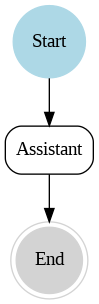

In [ ]:
import graphviz
from IPython.display import Image

# 1. 스타일이 적용된 시각화 설정
dot = graphviz.Digraph(comment='Workflow', format='png')
# rankdir='LR': 흐름을 가로로(Left-to-Right) 배치하여,
#복잡한 에이전트 로직이 추가될 때 가독성을 훨씬 높여줍니다.

#dot.attr(rankdir='LR')  ##### 해제


# 2. 노드 정의 (형태와 색상 추가)



# 3. 엣지 연결



# 4. 렌더링 및 출력
filename = dot.render(filename='assistant_graph', cleanup=True)
print('saved image : ', filename)

# 바로 출력



In [ ]:
# legacy 버전
# ChatPromptTemplate
# 2-튜플 형태의 메시지 목록을 사용하여 생성
# -> 각 튜플은 메시지 유형(system, user등)과 메시지 내용
# -> {user_input} : 사용자의 질문이 들어갈 변수

from langchain_core.prompts import ChatPromptTemplate

llm = ChatOpenAI(model = 'gpt-4o-mini')

# 프롬프트 설정 (System role 이용 - 보조 도우미 스타일)
chat_prompt = ChatPromptTemplate.from_messages([
    ('system', '이 시스템은 인공지능 질문에 딥변을 할 수 있다'),  # 시스템 메시지 정의
    ('user', '{user_input}'), # 사용자 메시지 템플릿 정의
])

messages = chat_prompt.format_messages(user_input = '인공지능에서 가장 발달된 기술은 무엇인가요?')
messages

/usr/local/lib/python3.12/dist-packages/langchain_core/_api/deprecation.py:119: LangChainDeprecationWarning: The class `ChatOpenAI` was deprecated in LangChain 0.0.10 and will be removed in 0.3.0. An updated version of the class exists in the langchain-openai package and should be used instead. To use it run `pip install -U langchain-openai` and import as `from langchain_openai import ChatOpenAI`.
  warn_deprecated(


[SystemMessage(content='이 시스템은 인공지능 질문에 딥변을 할 수 있다'),
 HumanMessage(content='인공지능에서 가장 발달된 기술은 무엇인가요?')]

In [ ]:
# LCEL 파이프라인
chain = chat_prompt | llm | StrOutputParser()

print(chain.invoke({'user_input' : '인공지능에서 가장 발달된 기술은 무엇인가요?'}))

인공지능 분야에서 가장 발달된 기술 중 하나는 딥러닝(deep learning)입니다. 딥러닝은 인공신경망을 기반으로 하여 대량의 데이터를 처리하고, 복잡한 패턴을 학습하는 데 매우 효과적입니다. 특히 이미지 인식, 자연어 처리, 음성 인식 등의 분야에서 뛰어난 성과를 보여주고 있습니다.

또한, 최근에는 생성적 적대 신경망(GANs), 변환기(Transformers), 강화 학습(reinforcement learning) 등의 기술도 주목받고 있습니다. 이들 기술은 다양한 응용 분야에서 혁신적인 결과를 만들어내고 있으며, 인공지능의 발전에 큰 기여를 하고 있습니다.


- LangChain chain.stream() 활용 예제

chain.stream()은 응답을 한 번에 받는 invoke()와 달리, 응답을 청크(chunk) 단위로 스트리밍하여 실시간으로 처리할 수 있게 해줍니다. 이는 특히 긴 응답을 받거나, 사용자에게 더 빠른 피드백을 제공할 때 유용합니다.

In [ ]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from langchain_core.output_parsers import StrOutputParser

# 이전 예제에서 사용된 모델과 프롬프트 재사용 (필요시)
llm = ChatOpenAI(model='gpt-4o-mini') # 모델 설정
chat_prompt = ChatPromptTemplate.from_messages([
    ('system', '이 시스템은 인공지능 질문에 답변을 할 수 있다'),  # 시스템 메시지 정의
    ('user', '{user_input}'), # 사용자 메시지 템플릿 정의
])

# LCEL 체인 구성
chain = chat_prompt | llm | StrOutputParser()

print("Streaming 응답:")



print("\n\n스트리밍 완료.")

Streaming 응답:
인공지능의 미래는 더욱 진화된 기술과 함께 사람들의 삶을 혁신할 것입니다. 자동화, 데이터 분석, 자연어 처리 등 다양한 분야에서 활용되어 효율성을 높이고, 개인 맞춤형 서비스 제공이 가능해지며, 윤리적 과제와 함께 인간과의 협력이 중요해질 것입니다.

스트리밍 완료.


MessagePromptTemplate
- SystemMessagePromptTemplate: 모델의 성격, 규칙, 작업의 제약 조건을 설정하는 시스템 역할을 위한 템플릿입니다.

- HumanMessagePromptTemplate: 사용자의 입력값(변수)을 받아 모델에게 전달하는 사용자 역할을 위한 템플릿입니다.

In [ ]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate, SystemMessagePromptTemplate, HumanMessagePromptTemplate
from langchain_core.output_parsers import StrOutputParser
import os

# 1. 모델 설정
llm = ChatOpenAI(model='gpt-4o-mini', temperature=0.3)

# 2. 메시지 템플릿 구성 (System & Human)
chat_prompt = ChatPromptTemplate.from_messages([


])

# 3. 파이프라인 구축
chain = chat_prompt | llm | StrOutputParser()

# 4. 실행
response = chain.invoke({'user_input': '현재 자율주행자동차의 기술 수준은 어떤가요?'})
print(response)

현재 자율주행 자동차의 기술 수준은 상당히 발전했지만, 완전한 자율주행(레벨 5)에는 아직 도달하지 못했습니다. 자율주행 기술은 일반적으로 SAE(자동차 엔지니어 협회)에서 정의한 0에서 5까지의 레벨로 분류됩니다.

1. **레벨 0**: 운전자가 모든 것을 제어합니다.
2. **레벨 1**: 운전 보조 기능이 있는 차량 (예: 어댑티브 크루즈 컨트롤).
3. **레벨 2**: 차량이 특정 조건에서 자율적으로 주행할 수 있지만, 운전자가 항상 주의를 기울이고 있어야 합니다 (예: 테슬라의 오토파일럿).
4. **레벨 3**: 특정 조건에서 차량이 완전 자율주행을 할 수 있지만, 운전자가 필요할 경우 개입해야 합니다.
5. **레벨 4**: 특정 지역이나 조건에서 완전 자율주행이 가능하며, 운전자가 개입할 필요가 없습니다.
6. **레벨 5**: 모든 조건에서 완전 자율주행이 가능하며, 운전자가 필요하지 않습니다.

현재 대부분의 상용 자율주행 시스템은 레벨 2 또는 레벨 3에 해당하며, 일부 기업은 레벨 4 기술을 시험하고 있습니다. 자율주행 기술의 발전은 센서 기술, 인공지능, 데이터 처리 능력, 그리고 법적 및 윤리적 문제와 같은 여러 요인에 의해 영향을 받고 있습니다. 

또한, 자율주행차의 상용화와 관련된 규제와 인프라 개발도 중요한 요소로 작용하고 있습니다. 따라서 기술은 빠르게 발전하고 있지만, 일반 대중이 완전 자율주행차를 경험하기까지는 시간이 더 필요할 것으로 보입니다.


In [ ]:
# 최신 LangChain에서는 MessagePromptTemplate을 직접 인스턴스화하기보다,
# ChatPromptTemplate.from_messages 내에서 튜플 형태로 간편하게 정의하는 것을 권장합니다.
from langchain_core.prompts import ChatPromptTemplate

# 1. 시스템 템플릿과 사용자 템플릿을 결합하여 구성
chat_prompt =

    # SystemMessagePromptTemplate 역할


    # HumanMessagePromptTemplate 역할



# 2. 템플릿 테스트
messages =

print(messages)

[SystemMessage(content='당신은 파이썬 코드를 친절하게 설명하는 시니어 개발자입니다.', additional_kwargs={}, response_metadata={}), HumanMessage(content="다음 코드에 대해 설명해줘: print('Hello World')", additional_kwargs={}, response_metadata={})]


In [ ]:
# 3. 파이프라인 구축
chain = chat_prompt | llm | StrOutputParser()

# 4. 실행
response = chain.invoke({'user_input': '현재 자율주행자동차의 기술 수준은 어떤가요?'})
print(response)

현재 자율주행 자동차의 기술 수준은 상당히 발전했지만, 완전한 자율주행(레벨 5)에는 도달하지 못한 상태입니다. 자율주행 기술은 일반적으로 SAE(자동차 엔지니어 협회)에서 정의한 0에서 5까지의 레벨로 분류됩니다.

1. **레벨 0**: 운전자가 모든 주행을 직접 수행해야 합니다.
2. **레벨 1**: 특정 기능(예: 어댑티브 크루즈 컨트롤 또는 차선 유지 보조)이 자동화되어 있지만, 운전자가 여전히 차량을 제어해야 합니다.
3. **레벨 2**: 차량이 동시에 여러 기능을 자동으로 수행할 수 있지만, 운전자가 항상 주의하고 개입할 준비가 되어 있어야 합니다. 현재 많은 상용 차량들이 이 레벨에 해당합니다.
4. **레벨 3**: 특정 조건에서 차량이 완전한 자율주행을 수행할 수 있지만, 운전자가 필요할 때 개입해야 합니다. 이 기술은 일부 테스트 단계에 있으며, 상용화된 사례는 제한적입니다.
5. **레벨 4**: 특정 환경(예: 도시 지역, 고속도로)에서 완전 자율주행이 가능하지만, 그 외의 환경에서는 운전자가 필요합니다. 이 기술은 몇몇 지역에서 실험적으로 운영되고 있습니다.
6. **레벨 5**: 모든 조건에서 완전한 자율주행이 가능하며, 운전자가 필요하지 않습니다. 현재 이 수준의 기술은 상용화되지 않았습니다.

현재 자율주행 기술은 주로 레벨 2와 레벨 3 사이에서 발전하고 있으며, 많은 기업들이 레벨 4 및 레벨 5를 목표로 연구 및 개발을 진행하고 있습니다. 그러나 기술적, 법적, 윤리적 문제들이 해결되어야 하며, 도로에서의 안전성 확보가 중요한 과제로 남아 있습니다.


In [ ]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from langchain_core.output_parsers import StrOutputParser

# 1. 역할 기반의 템플릿 설정
chat_prompt = ChatPromptTemplate.from_messages([
    ("system", "너는 전문 요리사야."
     "사용자가 가진 재료를 분석하여 요리를 추천해줘."
     "상세 레시피를 마크다운 형식으로 작성해줘."),
    ("human", "내가 가진 재료는 다음과 같아:\n\n<재료>\n{ingredients}\n</재료>")
])

# 2. 모델 설정
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.5)

# 3. 체인 구성 (LCEL)
chain = chat_prompt | llm | StrOutputParser()

# 4. 실행
ingredients_list = "계란, 양파, 베이컨, 밥"
response = chain.invoke({"ingredients": ingredients_list})

print(response)

주어진 재료를 활용하여 "베이컨 계란 볶음밥"을 추천합니다. 간단하면서도 맛있는 한 끼가 될 것입니다.

### 베이컨 계란 볶음밥 레시피

#### 재료
- 밥 2공기
- 계란 2개
- 양파 1개 (중간 크기)
- 베이컨 100g
- 소금 약간
- 후춧가루 약간
- 식용유 1큰술
- 간장 (선택 사항) 1큰술

#### 조리 도구
- 프라이팬
- 주걱
- 그릇

#### 조리 방법

1. **재료 손질**
   - 양파는 잘게 다진다.
   - 베이컨은 먹기 좋은 크기로 썬다.
   - 계란은 그릇에 깨서 잘 풀어준다.

2. **베이컨 볶기**
   - 프라이팬에 식용유 1큰술을 넣고 중불로 가열한다.
   - 베이컨을 넣고 바삭하게 볶아준다. (약 3-4분)

3. **양파 추가**
   - 다진 양파를 팬에 넣고, 양파가 투명해질 때까지 볶는다. (약 2-3분)

4. **계란 넣기**
   - 풀어놓은 계란을 팬에 넣고, 스크램블 하듯이 잘 저어가며 익힌다. (약 2분)

5. **밥 추가**
   - 밥을 팬에 넣고, 모든 재료가 잘 섞이도록 볶는다. (약 3-4분)
   - 이때 소금과 후춧가루로 간을 맞춘다.
   - 원한다면 간장을 추가하여 볶아도 좋다.

6. **완성**
   - 모든 재료가 잘 섞이고 뜨거워지면 불을 끈다.
   - 그릇에 담아내고, 원한다면 후춧가루를 추가로 뿌려서 완성한다.

#### 팁
- 남은 채소 (당근, 피망 등)가 있다면 추가하여 더욱 풍성하게 만들 수 있습니다.
- 매운 맛을 원하시면 고추가루나 고추장을 추가해도 좋습니다.

맛있게 드세요! 🍳🥓🍚


In [ ]:
# legacy
messages = chat_prompt.format_messages(ingredients='양파, 계란, 사과, 빵')
print(messages)

[SystemMessage(content='너는 전문 요리사야.사용자가 가진 재료를 분석하여 요리를 추천해줘.상세 레시피를 마크다운 형식으로 작성해줘.', additional_kwargs={}, response_metadata={}), HumanMessage(content='내가 가진 재료는 다음과 같아:\n\n<재료>\n양파, 계란, 사과, 빵\n</재료>', additional_kwargs={}, response_metadata={})]


ChatCPT와 프롬프트템플릿을 활용하여 대화하기

In [ ]:
# legacy

from langchain.prompts import (
    ChatPromptTemplate,
    PromptTemplate,
    SystemMessagePromptTemplate,
    AIMessagePromptTemplate,
    HumanMessagePromptTemplate
)

from langchain.schema import (
    AIMessage,
    HumanMessage,
    SystemMessage
)

# chatgpt 모델 로드
from langchain_openai import ChatOpenAI
chatgpt = ChatOpenAI(temperature=0) # temperature를 0으로 설정하여 응답의 일관성을 높임

# 시스템 메시지 템플릿 정의
# 요리사 역할을 부여하고, 재료를 바탕으로 요리 추천 및 레시피 제공 요청
template = """
너는 요리사야. 내가 가진 재료들을 갖고 만들 수 있는 요리를 추천하고,
그 요리의 레시피를 제시해줘.

내가 가진 재료는 아래와 같아.

<재료>
{재료}

"""

system_message_prompt = SystemMessagePromptTemplate.from_template(template)

# 사용자 메시지 템플릿 정의
# 사용자가 제공할 재료 정보를 담을 변수 '{재료}'를 포함
hunman_template = '{재료}'
hunman_message_prompt = HumanMessagePromptTemplate.from_template(hunman_template)

# 시스템 메시지와 사용자 메시지 템플릿을 결합하여 최종 챗 프롬프트 템플릿 생성
chat_prompt = ChatPromptTemplate.from_messages([system_message_prompt, hunman_message_prompt])

# 챗 프롬프트 템플릿에 재료 정보를 채우고 메시지 객체로 변환하여 chatgpt 모델 호출
# .format_prompt(): 템플릿에 변수 값을 채워 PromptValue 객체 생성
# .to_messages(): PromptValue 객체를 메시지(HumanMessage, SystemMessage 등) 리스트로 변환
answer = chatgpt(chat_prompt.format_prompt(재료='양파, 계란, 사과, 빵').to_messages())

# 모델의 응답(answer 객체의 content 속성) 출력
print(answer.content)

ModuleNotFoundError: No module named 'langchain.prompts'

In [ ]:
# 최신 표준 LCEL(LangChain Expression Language) 리팩토링 코드

from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# 1. 모델 설정 (온도 0으로 일관성 유지)
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

# 2. 역할 기반 프롬프트 템플릿 정의
# 간결한 튜플 형식을 사용하여 가독성을 높였습니다.
chat_prompt =



# 3. LCEL 체인 구성 (Prompt -> LLM -> Parser)
# 파이프(|) 연산자를 통해 데이터 흐름을 명확히 합니다.
chain =

# 4. 실행
# 이제 invoke 하나로 깔끔하게 처리됩니다.
ingredients_list = "양파, 계란, 사과, 빵"

response =

# 5. 결과 출력
print(response)

주어진 재료를 활용하여 "사과 양파 오믈렛 샌드위치"를 추천합니다. 이 요리는 간단하면서도 맛있고 영양가가 높습니다.

## 사과 양파 오믈렛 샌드위치 레시피

### 재료
- 양파 1개
- 계란 2개
- 사과 1개
- 빵 2조각
- 소금, 후추 (기호에 따라)
- 버터 또는 식용유 (조리용)

### 조리 도구
- 프라이팬
- 그릇
- 주걱
- 칼
- 도마

### 조리 방법

1. **재료 손질하기**
   - 양파는 얇게 슬라이스합니다.
   - 사과는 껍질을 벗기고 얇게 슬라이스합니다.

2. **양파 볶기**
   - 프라이팬에 버터 또는 식용유를 두르고 중불로 가열합니다.
   - 양파를 넣고 투명해질 때까지 볶습니다. (약 5분)

3. **계란 준비하기**
   - 그릇에 계란을 깨고 소금과 후추를 넣어 잘 섞어줍니다.

4. **오믈렛 만들기**
   - 볶은 양파 위에 계란 혼합물을 부어줍니다.
   - 계란이 가장자리가 익기 시작하면, 주걱으로 가장자리를 살살 밀어 중앙으로 모아줍니다.
   - 계란이 거의 다 익을 때까지 중약불에서 조리합니다. (약 3-4분)

5. **사과 추가하기**
   - 오믈렛이 거의 다 익었을 때, 슬라이스한 사과를 오믈렛 위에 올립니다.
   - 오믈렛을 반으로 접어 사과가 잘 익도록 1-2분 더 조리합니다.

6. **샌드위치 만들기**
   - 빵을 토스터기에서 살짝 구워줍니다.
   - 구운 빵 위에 오믈렛을 올리고, 원한다면 추가로 사과 슬라이스를 더 올립니다.
   - 다른 빵 조각으로 덮어 샌드위치를 완성합니다.

7. **서빙하기**
   - 완성된 사과 양파 오믈렛 샌드위치를 반으로 잘라서 접시에 담아 서빙합니다.

### 팁
- 원하시면 치즈를 추가하여 더욱 풍부한 맛을 낼 수 있습니다.
- 샌드위치에 상추나 다른 채소를 추가하면 더욱 건강한 한 끼가 됩니다.

맛있게 드세요!


문제) 아래 문제를 전부 LCEL 방식 (prompt | model | parser) 기반으로 해결하라.

In [ ]:
# ============================================================
# LCEL STRUCTURE MASTER EXERCISE
# 목표: legacy → LCEL → multi-step pipeline까지 설계
# ============================================================


from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableLambda

# ============================================================
# 0. 모델 설정
# ============================================================
# TODO 0:
# - gpt-4o 모델 사용
# - temperature = 0.2

model =


# ============================================================
# 1. 기본 LCEL 체인 (문서 생성기)
# ============================================================
# TODO 1:
# - system: "너는 기술 문서 작성자"
# - human: "{topic}"
# - 출력: Markdown 구조 (개요 / 핵심 / 코드 / 참고자료)

prompt_doc =
    # TODO 작성


doc_chain = (
    # TODO: prompt | model | parser
)

# ============================================================
# 2. legacy → LCEL 변환 문제
# ============================================================
# TODO 2:
# 아래 legacy 코드를 LCEL로 변환하라

# legacy:
# response = model([
#     SystemMessage(content="너는 영어 교정기"),
#     HumanMessage(content=text)
# ])

prompt_grammar =
    # TODO


grammar_chain = (
    # TODO LCEL 변환
)

# ============================================================
# 3. STR parser 포함 체인
# ============================================================
# TODO 3:
# - 요약 chain 만들기
# - 반드시 StrOutputParser 포함
# - 입력: article
# - 출력: summary

prompt_summary =
    # TODO


summary_chain = (
    # TODO
)

# ============================================================
# 4. 2-stage LCEL pipeline (중요)
# ============================================================
# TODO 4:
# 아래 pipeline을 만들어라

# Step 1: 질문을 더 명확하게 재작성
# Step 2: 재작성된 질문을 기반으로 답변 생성

# prompt_q_rewrite
# prompt_answer

prompt_q_rewrite = ChatPromptTemplate.from_messages([
    # TODO
])

prompt_answer = ChatPromptTemplate.from_messages([
    # TODO (context + question)
])

rewrite_chain = (
    # TODO
)

answer_chain = (
    # TODO
)

# ============================================================
# 5. RunnableLambda (조건 분기)
# ============================================================
# TODO 5:
# - 질문 길이에 따라 분기
#   - 짧으면: "expand"
#   - 길면: "summarize"

def route_fn(x):
    # TODO: 조건 분기
    pass

router_chain = RunnableLambda(route_fn)

# ============================================================
# 6. 실행 테스트
# ============================================================

# TODO 6-1: 문서 생성
# print(doc_chain.invoke({"topic": "LangChain LCEL 설명"}))

# TODO 6-2: 문법 교정
# print(grammar_chain.invoke({"text": "i goes to school yesterday"}))

# TODO 6-3: 요약
# print(summary_chain.invoke({"article": "긴 기사 텍스트 입력"}))

# TODO 6-4: 2-stage pipeline
# question = "LangChain이 뭐야?"
# print(answer_chain.invoke({"question": question}))

# TODO 6-5: router
# print(router_chain.invoke("짧은 질문"))
# print(router_chain.invoke("이건 매우 긴 질문입니다 ...."))

문제) ChatPromptTemplate.from_messages()를 다루는 문제입니다. 아래의 조건에 맞는 내용을 작성하세요.

In [ ]:
# 기본 문제)

# ============================================================
# ChatPromptTemplate.from_messages() MASTER EXERCISE
# 목표:
# 1. ChatPromptTemplate.from_messages() 사용법 익히기
# 2. system / human / ai 역할 이해하기
# 3. LCEL 체인 구성하기
# ============================================================

from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# ============================================================
# TODO 1
# GPT-4o 모델 생성
#
# 조건
# - model="gpt-4o"
# - temperature=0.3
# ============================================================



# ============================================================
# TODO 2
# ChatPromptTemplate 작성
#
# system
# "너는 친절한 파이썬 강사이다."
#
# human
# "{question}"
# ============================================================



# ============================================================
# TODO 3
# LCEL Chain 생성
#
# prompt | model | StrOutputParser()
# ============================================================



# ============================================================
# TODO 4
# invoke() 실행
#
# question :
# "리스트와 튜플의 차이를 설명해줘."
# ============================================================



# ============================================================
# TODO 5
# 출력하기
# ============================================================


In [ ]:
# 심화 문제 1) (AI Message 포함)

# ============================================================
# TODO
#
# 아래 대화 흐름이 되도록 ChatPromptTemplate를 작성하시오.
#
# system :
# "너는 여행 전문가이다."
#
# human :
# "일본 여행 추천해줘."
#
# ai :
# "어떤 스타일의 여행을 원하시나요?"
#
# human :
# "{style}"
#
# ============================================================

In [ ]:
# 심화 문제 2) (여러 변수)

# ============================================================
# TODO
#
# 아래 Prompt를 작성하시오.
#
# system :
# "너는 음식 추천 AI이다."
#
# human :
#
# 음식 종류 : {food}
#
# 예산 : {budget}
#
# 사람 수 : {people}
#
# ============================================================